In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df_rt = pd.read_csv('returns_clean.csv')
df_rw = pd.read_csv('reviews_clean.csv')

In [4]:
df_rw.info()

<class 'pandas.DataFrame'>
RangeIndex: 18854 entries, 0 to 18853
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   review_id    18854 non-null  str  
 1   order_id     18854 non-null  str  
 2   product_id   18854 non-null  str  
 3   customer_id  18854 non-null  str  
 4   rating       18854 non-null  int64
 5   review_date  18854 non-null  str  
 6   review_text  18854 non-null  str  
dtypes: int64(1), str(6)
memory usage: 1.7 MB


In [7]:
df_rw['review_date'] = pd.to_datetime(df_rw['review_date'])

In [6]:
df_rt.info()

<class 'pandas.DataFrame'>
RangeIndex: 2092 entries, 0 to 2091
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   return_id      2092 non-null   str    
 1   order_id       2092 non-null   str    
 2   product_id     2092 non-null   str    
 3   return_date    2092 non-null   str    
 4   return_reason  2092 non-null   str    
 5   refund_amount  2092 non-null   float64
 6   sales_amount   2092 non-null   float64
dtypes: float64(2), str(5)
memory usage: 200.0 KB


In [8]:
df_rt['return_date'] = pd.to_datetime(df_rt['return_date'])

In [9]:
df_rt.info()


<class 'pandas.DataFrame'>
RangeIndex: 2092 entries, 0 to 2091
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   return_id      2092 non-null   str           
 1   order_id       2092 non-null   str           
 2   product_id     2092 non-null   str           
 3   return_date    2092 non-null   datetime64[us]
 4   return_reason  2092 non-null   str           
 5   refund_amount  2092 non-null   float64       
 6   sales_amount   2092 non-null   float64       
dtypes: datetime64[us](1), float64(2), str(4)
memory usage: 179.6 KB


In [11]:
df_rw.info()

<class 'pandas.DataFrame'>
RangeIndex: 18854 entries, 0 to 18853
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   review_id    18854 non-null  str           
 1   order_id     18854 non-null  str           
 2   product_id   18854 non-null  str           
 3   customer_id  18854 non-null  str           
 4   rating       18854 non-null  int64         
 5   review_date  18854 non-null  datetime64[us]
 6   review_text  18854 non-null  str           
dtypes: datetime64[us](1), int64(1), str(5)
memory usage: 1.6 MB


### 1. Marking which reviewed orders were returned

In [14]:
df_rw['returned'] = df_rw['order_id'].isin(df_rt['order_id'])

In [16]:
df_rw.head()

,review_id,order_id,product_id,customer_id,rating,review_date,review_text,returned
0,R010604,O022818,P0511,C02067,3,2023-08-11,Average,False
1,R009801,O010197,P0587,C01819,5,2025-01-11,Excellent,False
2,R004955,O009108,P0589,C02962,3,2023-11-29,Average,False
3,R007671,O006765,P0122,C04227,4,2025-01-21,Good,False
4,R013835,O026125,P0555,C04787,5,2025-01-16,Excellent,False


In [23]:
print('Overall return %age of reviewed orders :', round(df_rw['returned'].mean()*100, 1))

Overall return %age of reviewed orders : 8.5


### 2. Return rate for each rating (1 to 5)

In [30]:
by = df_rw.groupby(df_rw['rating'])['returned'].agg(reviews = 'count', returns ='sum', return_rate = 'mean').reset_index()

In [31]:
by

,rating,reviews,returns,return_rate
0,1,456,121,0.265351
1,2,2201,538,0.244434
2,3,5231,324,0.061938
3,4,5922,350,0.059102
4,5,5044,279,0.055313


In [39]:
#by['return_rate'] = round(by['return_rate']*100, 1)

In [40]:
by

,rating,reviews,returns,return_rate
0,1,456,121,26.5
1,2,2201,538,24.4
2,3,5231,324,6.2
3,4,5922,350,5.9
4,5,5044,279,5.5


### 3. Grouping into low, medium and high ratings

In [41]:
df_rw['group'] = df_rw['rating'].map({1: 'Low', 2: 'Low', 3: 'Medium', 4:'High', 5:'High'})

In [42]:
df_rw['group']

0        Medium
1          High
2        Medium
3          High
4          High
          ...  
18849      High
18850      High
18851      High
18852      High
18853    Medium
Name: group, Length: 18854, dtype: str

In [44]:
g = df_rw.groupby('group')['returned'].mean().mul(100).reindex(['Low', 'Medium', 'High']).reset_index(name = 'return_rate')

In [45]:
g

,group,return_rate
0,Low,24.802409
1,Medium,6.193844
2,High,5.735911


### 4. Checking it for each product, not just each review

In [49]:
p = df_rw.groupby('product_id').agg(return_rate = ('returned', 'mean'), avg_rating = ('rating', 'mean'), rating_count = ('rating', 'count')).reset_index()

In [51]:
p.head()

,product_id,return_rate,avg_rating,rating_count
0,P0001,0.187500,3.500000,16
1,P0002,0.000000,3.500000,4
2,P0003,0.000000,4.608696,23
3,P0004,0.142857,4.571429,7
4,P0005,0.052632,4.842105,19


In [52]:
p = p[p['rating_count']>= 15]

In [54]:
p.head()

,product_id,return_rate,avg_rating,rating_count
0,P0001,0.187500,3.500000,16
2,P0003,0.000000,4.608696,23
4,P0005,0.052632,4.842105,19
5,P0006,0.130435,2.478261,23
6,P0007,0.117647,4.117647,17


In [55]:
p['return_rate'] = round(p['return_rate']*100, 1)

In [57]:
p.head()

,product_id,return_rate,avg_rating,rating_count
0,P0001,18.8,3.500000,16
2,P0003,0.0,4.608696,23
4,P0005,5.3,4.842105,19
5,P0006,13.0,2.478261,23
6,P0007,11.8,4.117647,17


In [61]:
print('Correlation:',round(p['avg_rating'].corr(p['return_rate']), 1))

Correlation: -0.5


## VISUALIZATION

### 1. Return rate for each rating (bar)

In [63]:
by.head()

,rating,reviews,returns,return_rate
0,1,456,121,26.5
1,2,2201,538,24.4
2,3,5231,324,6.2
3,4,5922,350,5.9
4,5,5044,279,5.5


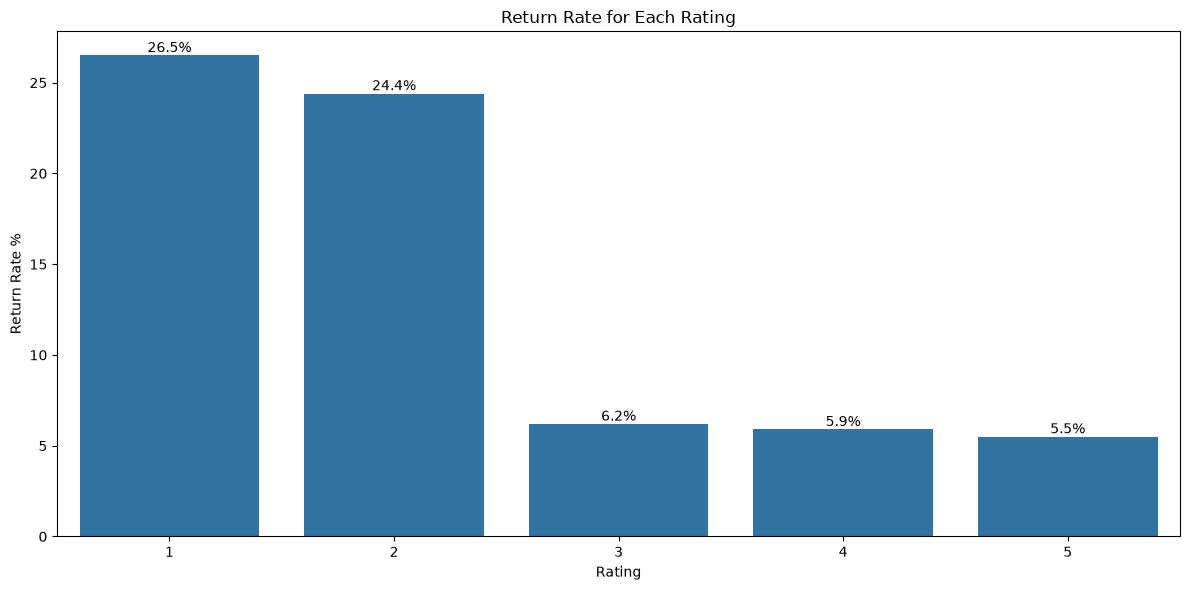

In [68]:
plt.figure(figsize = (12,6))
a = sns.barplot(data = by, x = 'rating', y = 'return_rate')
a.bar_label(a.containers[0], fmt = '%.1f%%')
plt.title('Return Rate for Each Rating')
plt.xlabel('Rating')
plt.ylabel('Return Rate %')
plt.tight_layout()
plt.show()

### 2. Low vs medium vs high ratings (bar)

In [69]:
g

,group,return_rate
0,Low,24.802409
1,Medium,6.193844
2,High,5.735911


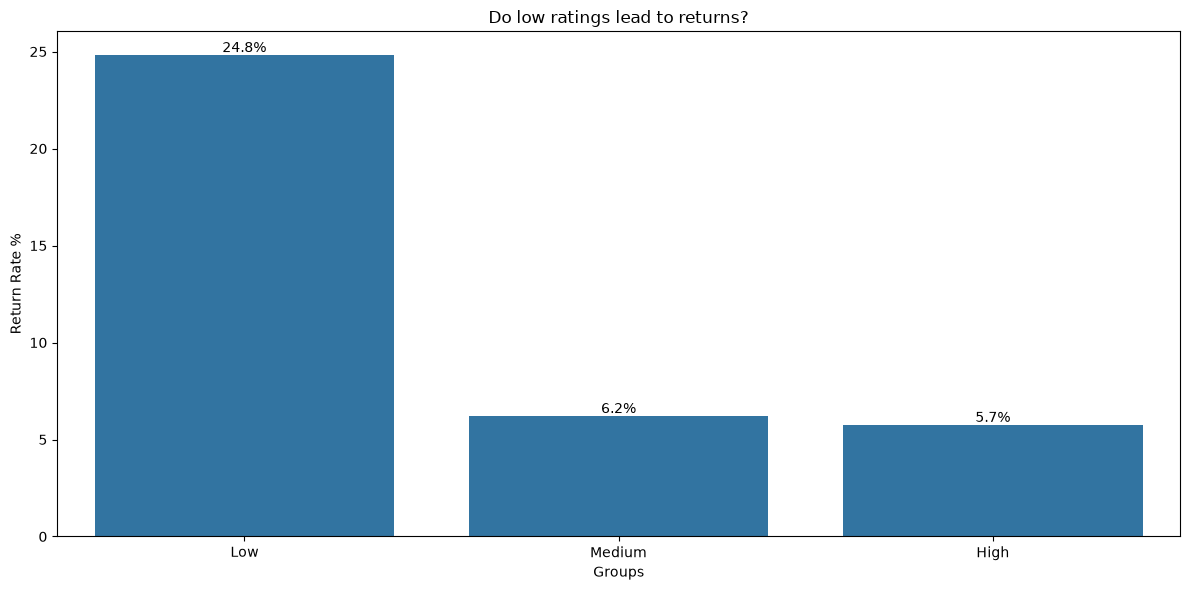

In [71]:
plt.figure(figsize = (12,6))
a = sns.barplot(data = g, x = 'group', y = 'return_rate')
a.bar_label(a.containers[0], fmt = '%.1f%%')
plt.title('Do low ratings lead to returns?')
plt.xlabel('Groups')
plt.ylabel('Return Rate %')
plt.tight_layout()
plt.show()

### 3. Product average rating vs return rate

In [72]:
p

,product_id,return_rate,avg_rating,rating_count
0,P0001,18.8,3.500000,16
2,P0003,0.0,4.608696,23
4,P0005,5.3,4.842105,19
5,P0006,13.0,2.478261,23
6,P0007,11.8,4.117647,17
...,...,...,...,...
592,P0593,7.1,4.533333,255
593,P0594,43.8,2.750000,16
595,P0596,8.1,3.000000,37
596,P0597,5.0,4.050000,20


In [73]:
p.head()

,product_id,return_rate,avg_rating,rating_count
0,P0001,18.8,3.500000,16
2,P0003,0.0,4.608696,23
4,P0005,5.3,4.842105,19
5,P0006,13.0,2.478261,23
6,P0007,11.8,4.117647,17


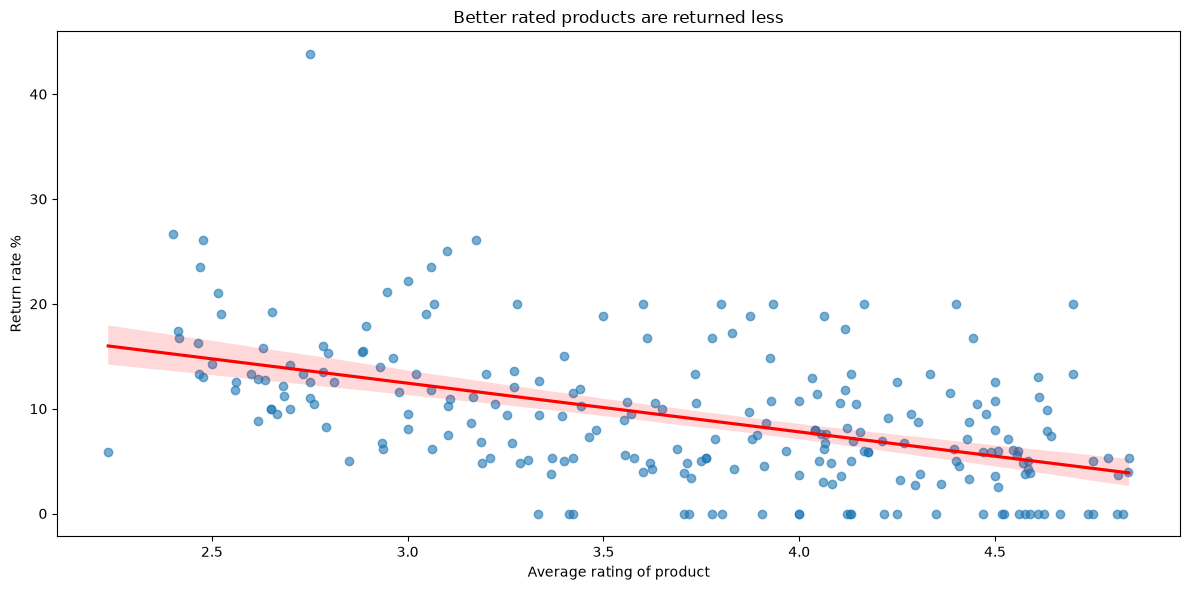

In [74]:
plt.figure(figsize=(12, 6))
sns.regplot(data=p, x='avg_rating', y='return_rate',scatter_kws={'alpha': 0.6}, line_kws={'color': 'red'})
plt.xlabel('Average rating of product'); plt.ylabel('Return rate %')
plt.title('Better rated products are returned less')
plt.tight_layout(); plt.show()

## CONCLUSION 